In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    silhouette_score
)

from mlxtend.frequent_patterns import apriori, association_rules

In [2]:
df=pd.read_csv('../data/raw/cleaned_retail_sales_data.csv')

In [3]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Customer ID'] = df['Customer ID'].astype('Int64')
df['StockCode'] = df['StockCode'].astype(str)

# Remove invalid transactions
df = df.dropna(subset=['Customer ID', 'InvoiceDate', 'StockCode'])
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]

# Calculate sales
df['TotalAmount'] = df['Quantity'] * df['Price']

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Category,TotalAmount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,"Seasonal, Party & Stationery",83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,Home Decor & Living,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,Home Decor & Living,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,Home Decor & Living,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,Home Decor & Living,30.0


In [4]:
# Reference date: one day after the last transaction
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

customer_data = df.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceDate', 'nunique'),
    Monetary=('TotalAmount', 'sum'),
    AvgOrderValue=('TotalAmount', 'mean'),
    TotalQuantity=('Quantity', 'sum')
).reset_index()

customer_data.head()

,Customer ID,Recency,Frequency,Monetary,AvgOrderValue,TotalQuantity
0,12346,165,11,372.86,11.298788,70
1,12347,3,2,1323.32,18.638310,828
2,12348,74,1,222.16,11.108000,373
3,12349,43,3,2671.14,26.187647,993
4,12351,11,1,300.93,14.330000,261


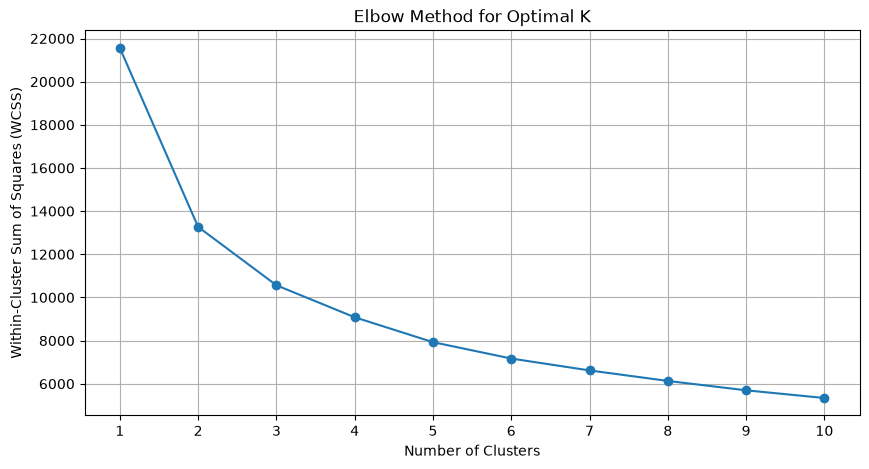

In [5]:
cluster_features = [
    'Recency',
    'Frequency',
    'Monetary',
    'AvgOrderValue',
    'TotalQuantity'
]

# Log-transform skewed values
X_cluster = customer_data[cluster_features].copy()

for col in ['Frequency', 'Monetary', 'AvgOrderValue', 'TotalQuantity']:
    X_cluster[col] = np.log1p(X_cluster[col])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Elbow Method
wcss = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(k_values, wcss, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

Best K by silhouette score: 2


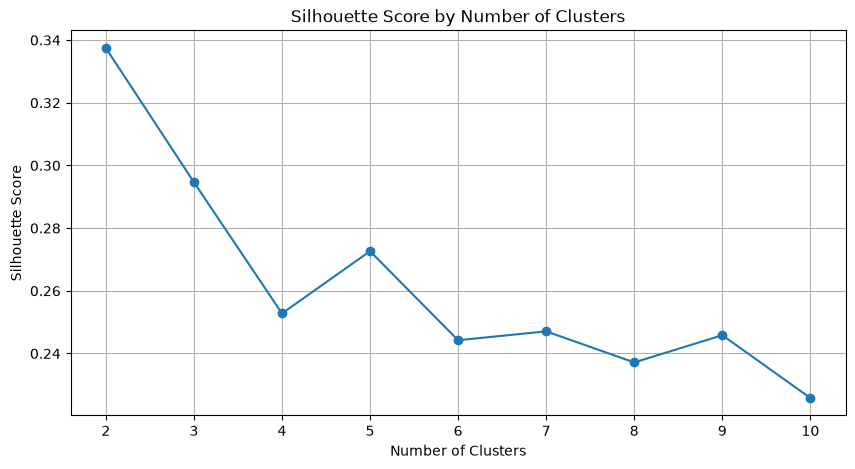

In [6]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(10, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

best_k = range(2, 11)[np.argmax(silhouette_scores)]
print("Best K by silhouette score:", best_k)

In [7]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

customer_data['Cluster'] = kmeans.fit_predict(X_scaled)

print(customer_data['Cluster'].value_counts().sort_index())

Cluster
0    1874
1    2438
Name: count, dtype: int64


In [8]:
cluster_summary = customer_data.groupby('Cluster')[cluster_features].mean()
display(cluster_summary.round(2))

# Save KMeans Model to artifacts folder
artifacts_dir = os.path.join('..', 'artifacts')
os.makedirs(artifacts_dir, exist_ok=True)
kmeans_artifact = {
    'model': kmeans,
    'scaler': scaler,
    'features': cluster_features,
    'best_k': best_k,
    'cluster_summary': cluster_summary
}
joblib.dump(kmeans_artifact, os.path.join(artifacts_dir, 'kmeans_model.pkl'))
joblib.dump(kmeans, os.path.join(artifacts_dir, 'kmeans.pkl'))
joblib.dump(scaler, os.path.join(artifacts_dir, 'kmeans_scaler.pkl'))
print("KMeans model saved to artifacts/kmeans_model.pkl")

KMeans model saved to artifacts/kmeans_model.pkl


,Recency,Frequency,Monetary,AvgOrderValue,TotalQuantity
Cluster,,,,,
0,39.73,8.11,4151.90,40.41,2651.77
1,130.71,1.63,417.38,34.39,225.66


# RANDOM FOREST

In [9]:
monthly_demand = (
    df.set_index('InvoiceDate')
      .groupby('StockCode')['Quantity']
      .resample('MS')
      .sum()
      .reset_index()
)

monthly_demand = monthly_demand.rename(
    columns={'InvoiceDate': 'Month', 'Quantity': 'Demand'}
)

monthly_demand = monthly_demand.sort_values(
    ['StockCode', 'Month']
).reset_index(drop=True)

monthly_demand.head()

,StockCode,Month,Demand
0,10002,2009-12-01,212
1,10002,2010-01-01,289
2,10002,2010-02-01,255
3,10002,2010-03-01,633
4,10002,2010-04-01,1129


In [10]:
monthly_demand['MonthNumber'] = monthly_demand['Month'].dt.month
monthly_demand['Year'] = monthly_demand['Month'].dt.year

# Historical demand features (using 1, 2, 3 month lags for 1-year data)
for lag in [1, 2, 3]:
    monthly_demand[f'Lag_{lag}'] = (
        monthly_demand.groupby('StockCode')['Demand'].shift(lag)
    )

# Rolling averages using only previous months
monthly_demand['RollingMean_3'] = (
    monthly_demand.groupby('StockCode')['Demand']
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

# Remove rows without sufficient historical data
model_data = monthly_demand.dropna().copy()

# Label encode StockCode for Random Forest
le = LabelEncoder()
model_data['StockCode_Encoded'] = le.fit_transform(model_data['StockCode'])

features = [
    'StockCode_Encoded',
    'MonthNumber',
    'Year',
    'Lag_1',
    'Lag_2',
    'Lag_3',
    'RollingMean_3'
]

X = model_data[features]
y = model_data['Demand']
print(f"Prepared model data: {X.shape[0]} rows, {X.shape[1]} features")

Prepared model data: 26382 rows, 7 features


In [11]:
# Use the last 20% of unique months for testing
unique_months = sorted(model_data['Month'].unique())
split_index = int(len(unique_months) * 0.8)
test_start = unique_months[split_index]

train_mask = model_data['Month'] < test_start
test_mask = model_data['Month'] >= test_start

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

# Save Random Forest Model to artifacts folder
artifacts_dir = os.path.join('..', 'artifacts')
os.makedirs(artifacts_dir, exist_ok=True)
rf_artifact = {
    'model': rf_model,
    'label_encoder': le,
    'features': features,
    'metrics': {'mae': mae, 'rmse': rmse, 'r2': r2}
}
joblib.dump(rf_artifact, os.path.join(artifacts_dir, 'random_forest_model.pkl'))
joblib.dump(rf_model, os.path.join(artifacts_dir, 'random_forest.pkl'))
print("Random Forest model saved to artifacts/random_forest_model.pkl")

MAE: 191.05420943609204
RMSE: 421.4427407765232
R²: 0.23118773631640177
Random Forest model saved to artifacts/random_forest_model.pkl


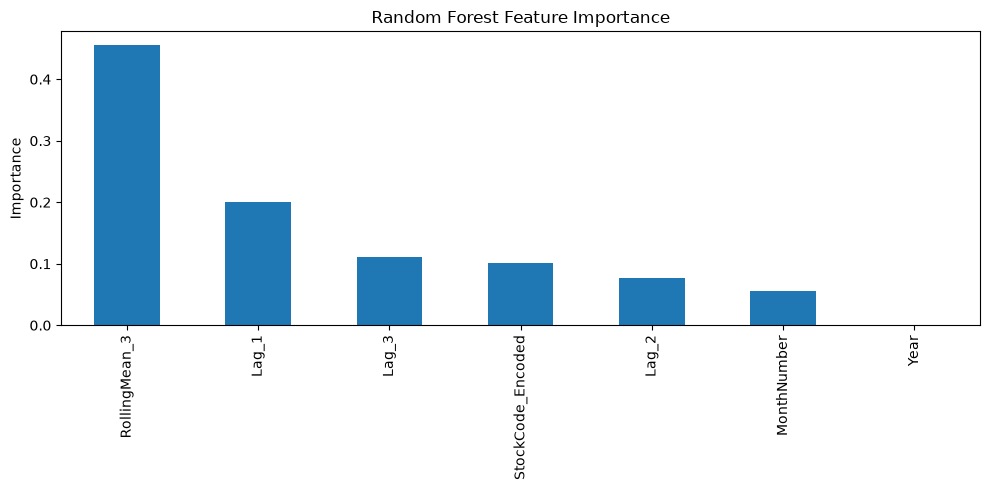

In [12]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)

importance.plot(kind='bar', figsize=(10, 5))
plt.title('Random Forest Feature Importance')
plt.ylabel('Importance')
plt.tight_layout()
plt.show()

In [13]:
latest_rows = (
    monthly_demand.sort_values('Month')
    .groupby('StockCode')
    .tail(1)
    .copy()
)

latest_rows['Month'] = latest_rows['Month'] + pd.offsets.MonthBegin(1)
latest_rows['MonthNumber'] = latest_rows['Month'].dt.month
latest_rows['Year'] = latest_rows['Month'].dt.year

# Recalculate lag features from the historical series
history = monthly_demand.sort_values(['StockCode', 'Month'])

for lag in [1, 2, 3]:
    lag_values = history.groupby('StockCode')['Demand'].apply(
        lambda x: x.iloc[-lag] if len(x) >= lag else np.nan
    )
    latest_rows[f'Lag_{lag}'] = latest_rows['StockCode'].map(lag_values)

rolling_values = history.groupby('StockCode')['Demand'].apply(
    lambda x: x.tail(3).mean() if len(x) >= 3 else np.nan
)
latest_rows['RollingMean_3'] = latest_rows['StockCode'].map(rolling_values)

# Encode StockCode for known codes
known_codes = set(le.classes_)
latest_rows = latest_rows[latest_rows['StockCode'].isin(known_codes)].copy()
latest_rows['StockCode_Encoded'] = le.transform(latest_rows['StockCode'])

forecast_data = latest_rows.dropna(subset=features)
forecast_data['PredictedDemand'] = rf_model.predict(
    forecast_data[features]
)

forecast_data[['StockCode', 'Month', 'PredictedDemand']].head(10)

# APRIORI FOR RECOMMENDATION

In [14]:
basket = (
    df.groupby(['Invoice', 'StockCode'])['Quantity']
      .sum()
      .unstack(fill_value=0)
)

# Convert quantities to binary presence/absence
basket = basket.gt(0)

basket.head()

StockCode  10002  10080  10109  10120  ...   POST  SP1002  TEST001  TEST002
Invoice                                ...                                 
489434     False  False  False  False  ...  False   False    False    False
489435     False  False  False  False  ...  False   False    False    False
489436     False  False  False  False  ...  False   False    False    False
489437      True  False  False  False  ...  False   False    False    False
489438     False  False  False  False  ...  False   False    False    False

[5 rows x 4017 columns]

In [15]:
frequent_itemsets = apriori(
    basket,
    min_support=0.01,
    use_colnames=True
)

frequent_itemsets = frequent_itemsets.sort_values(
    'support',
    ascending=False
)

frequent_itemsets.head(10)

,support,itemsets
603,0.157237,frozenset({85123A})
600,0.088898,frozenset({85099B})
352,0.087805,frozenset({22423})
83,0.079217,frozenset({21212})
89,0.069484,frozenset({21232})
564,0.069380,frozenset({84879})
23,0.068599,frozenset({20725})
174,0.061104,frozenset({21754})
577,0.059127,frozenset({84991})
33,0.054703,frozenset({20914})


In [16]:
rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=0.3
)

rules = rules.sort_values(
    ['lift', 'confidence'],
    ascending=False
)

rules[['antecedents', 'consequents', 'support',
       'confidence', 'lift']].head(10)

In [17]:
def recommend_products(product_code, rules, top_n=5):
    product_code = str(product_code)

    matching_rules = rules[
        rules['antecedents'].apply(
            lambda items: product_code in items
        )
    ].copy()

    matching_rules = matching_rules.sort_values(
        ['lift', 'confidence'],
        ascending=False
    )

    recommendations = []

    for _, row in matching_rules.iterrows():
        for item in row['consequents']:
            if item != product_code and item not in recommendations:
                recommendations.append(item)

            if len(recommendations) >= top_n:
                return recommendations

    return recommendations


# Example
product_code = df['StockCode'].iloc[0]

print("Product:", product_code)
print("Recommended products:", recommend_products(product_code, rules))

# Save Apriori Model and Rules to artifacts folder
artifacts_dir = os.path.join('..', 'artifacts')
os.makedirs(artifacts_dir, exist_ok=True)
item_desc = df.groupby('StockCode')['Description'].first().to_dict()

recommendations_lookup = {}
for code in df['StockCode'].unique():
    rec_list = recommend_products(code, rules, top_n=5)
    if rec_list:
        recommendations_lookup[str(code)] = rec_list

apriori_artifact = {
    'frequent_itemsets': frequent_itemsets,
    'rules': rules,
    'recommendations_lookup': recommendations_lookup,
    'item_descriptions': item_desc
}
joblib.dump(apriori_artifact, os.path.join(artifacts_dir, 'apriori_model.pkl'))
joblib.dump(rules, os.path.join(artifacts_dir, 'apriori_rules.pkl'))
print(f"Apriori model saved to artifacts/apriori_model.pkl with {len(recommendations_lookup)} product recommendation mappings.")

Product: 85048
Recommended products: []
Apriori model saved to artifacts/apriori_model.pkl with 169 product recommendation mappings.
